# Computer Vision - P2

### *Carefully read the following instructions before start coding.*

### **Recommended Preparation**

Before starting P2, it is **recommended that you complete the `p2_tutorial` first**. The tutorial introduces the key concepts and steps needed to complete the practice successfully. Completing it beforehand will help you understand the requirements and avoid common mistakes.


==============================================================================================
## **Practice 2: Image Filtering and Edge Detection**


==============================================================================================

### Main Topics

The main topics covered in this **practical exercise** are:

1. **Image smoothing and convolution** — Exercises 2.1, 2.2, 2.3, and 2.4
2. **Edge detection** — Exercises 2.5, 2.6, and 2.7

To complete this practical exercise, you should understand the following concepts:

* Linear filters
* Histograms
* Convolution
* Image edges

For additional information, refer to the following chapters of *Computer Vision: Algorithms and Applications* by Richard Szeliski:

* **Chapter 3 — Image Processing:** Point Operators and Linear Filtering
* **Chapter 4 — Feature Detection and Matching:** Edges
---

## **2.1 RGB histogram visualization**

**a)** Read the image `./images_notebook/plugs.png` and visualize the **RGB image** and each of its channels (**R, G, and B**) separately. Print the **image shape** and **data type**.

<img src="images_notebook/plugs.png">

> Expected output is illustrated below:

<img src="images_notebook/plugsb.jpg">

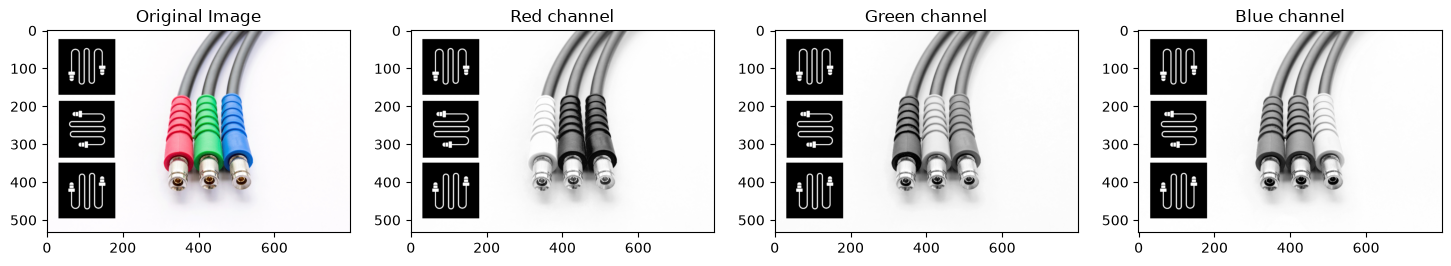

In [2]:
# Import the required libraries.
from skimage import io
from matplotlib import pyplot as plt
import numpy as np
from skimage import img_as_float
from skimage.color import rgb2gray

input_image = io.imread("./images_notebook/plugs.png")
fig = plt.figure(figsize=(18, 12))


fig.add_subplot(1, 4, 1)
plt.imshow(input_image)
plt.title('Original Image')

# Red channgel: channel 0
fig.add_subplot(1, 4, 2)
plt.imshow(input_image[:, :, 0], cmap='gray')
plt.title('Red channel')

# Green channel: channel 1
fig.add_subplot(1, 4, 3)
plt.imshow(input_image[:, :, 1], cmap='gray')
plt.title('Green channel')

# Blue channel: channel 2
fig.add_subplot(1, 4, 4)
plt.imshow(input_image[:, :, 2], cmap='gray')
plt.title('Blue channel')
plt.show()

**b)** Create a function named `rgb_im_hist(img, nbins=8)` that takes an **RGB image** as input and:

* Displays the **original RGB image**.
* Computes and displays the **histogram of each color channel (R, G, and B)**.
* Converts the image to **grayscale** and displays its histogram.
* Arranges all results **side by side** with appropriate captions.
* Uses `nbins` as an **input parameter** to specify the number of histogram bins. The value of `nbins` can range from **2 to 256**.

> **Note:** Test your function with `nbins = 8, 16, 32, 64, 128,` and `256` to make sure it works correctly for different numbers of histogram bins.

> Expected output is illustrated below (for `nbins=8`):

<img src="images_notebook/rgb_img_hist.jpg">

**Help:** [matplotlib image tutorial](https://matplotlib.org/users/image_tutorial.html)

In [10]:
from skimage.color import rgb2gray

def rgb_im_hist(img, nbins=8):
    fig = plt.figure(figsize=(18, 5))

    fig.add_subplot(1, 5, 1)
    plt.imshow(img)
    plt.title('Original Image')

    fig.add_subplot(1, 5, 2)
    plt.hist(img[:, :, 0].ravel(), bins=nbins)
    plt.title('Red channel')
    plt.xlabel('Pixel intensity')
    plt.ylabel('Frequency')

    fig.add_subplot(1, 5, 3)
    plt.hist(img[:, :, 1].ravel(), bins=nbins)
    plt.title('Green channel')
    plt.xlabel('Pixel intensity')
    plt.ylabel('Frequency')

    fig.add_subplot(1, 5, 4)
    plt.hist(img[:, :, 2].ravel(), bins=nbins)
    plt.title('Blue channel')
    plt.xlabel('Pixel intensity')
    plt.ylabel('Frequency')
    
    fig.add_subplot(1, 5, 5)
    plt.hist(rgb2gray(img).ravel(), bins=nbins)
    plt.title('Grayscale')
    plt.xlabel('Pixel intensity')
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

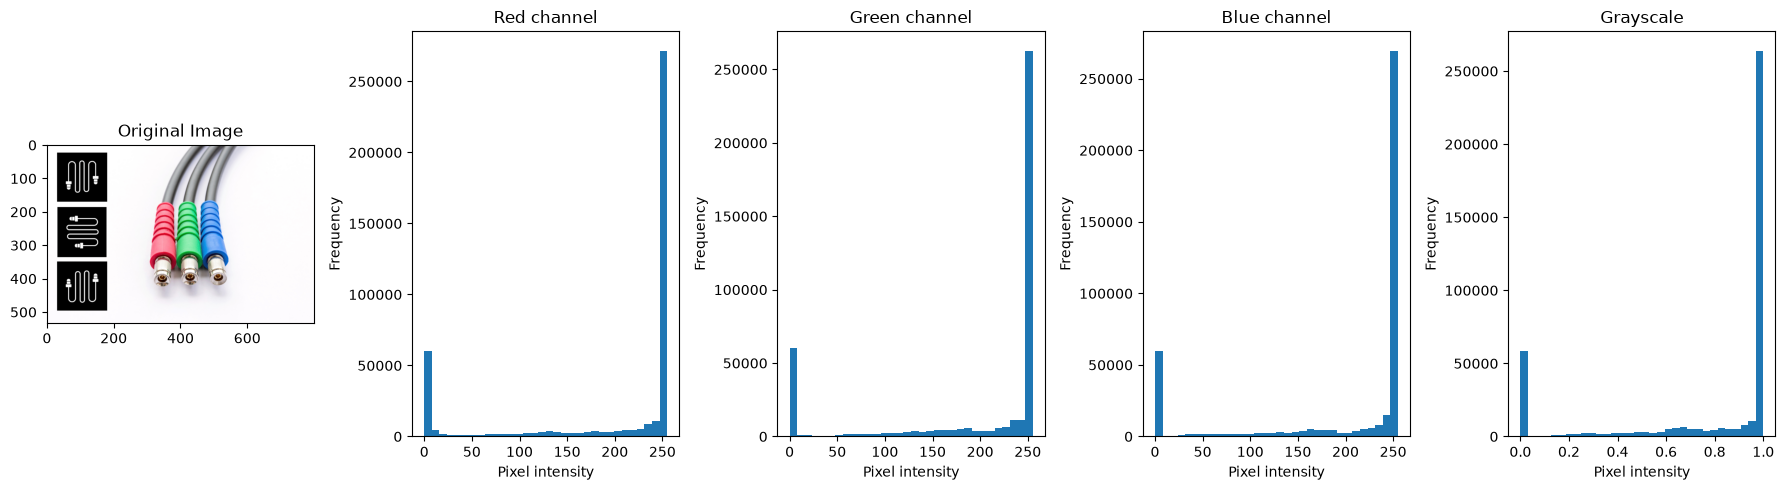

In [11]:
# Call the function with 32 histogram bins.
rgb_im_hist(input_image, nbins=32)

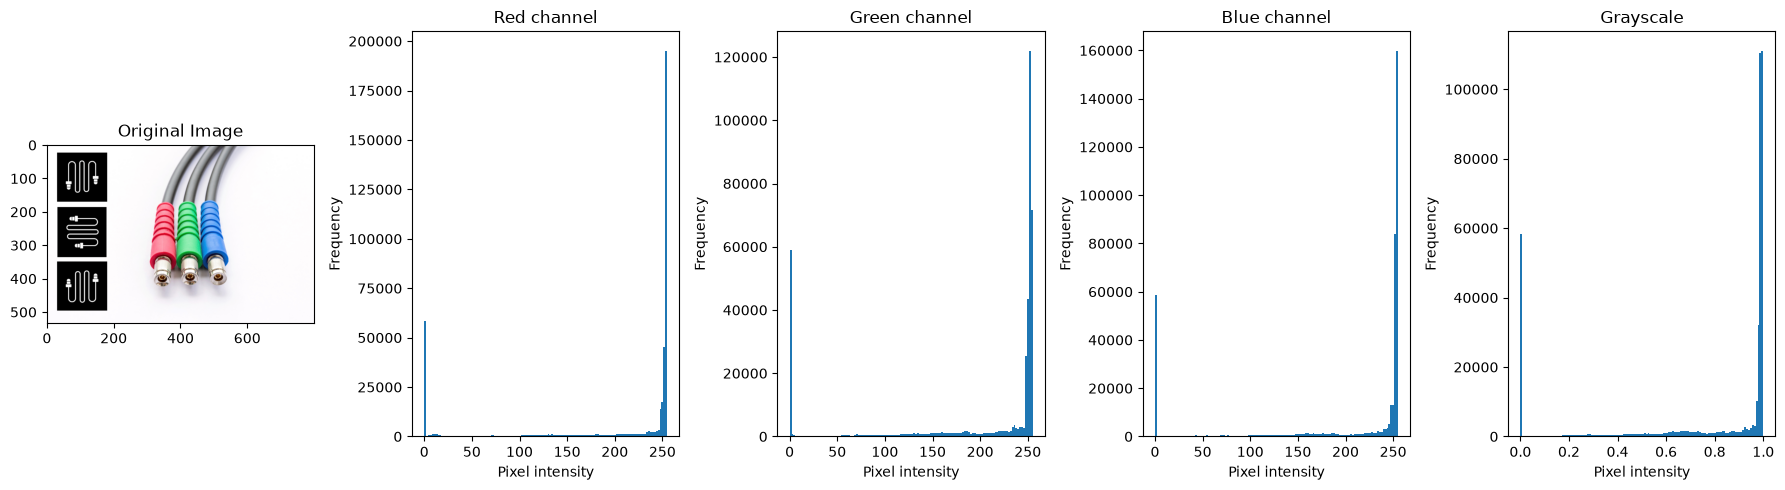

In [12]:
# Call the function with 128 histogram bins.
rgb_im_hist(input_image, nbins=128)

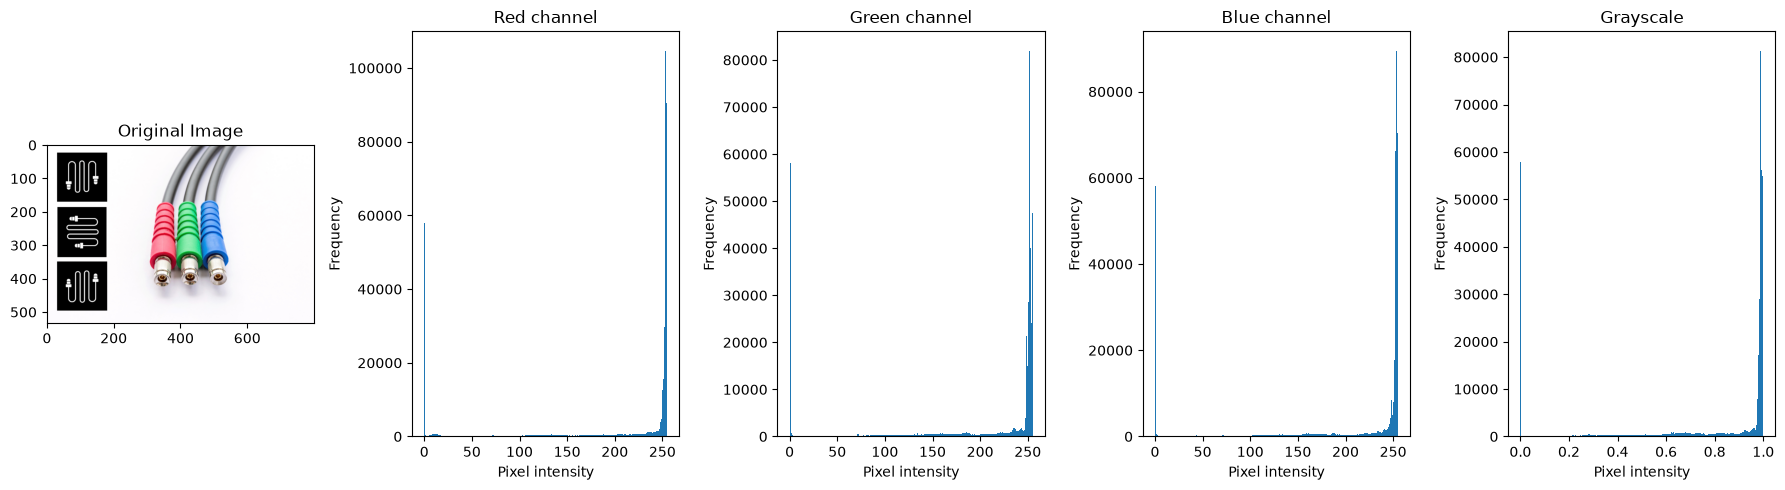

In [13]:
# Call the function with 256 histogram bins.
rgb_im_hist(input_image, nbins=256)

### Discussion

Analyse the plots obtained with different values of `nbins`. In particular, consider:

* How increasing the number of bins affects the **appearance and level of detail** of the histograms.
* The differences between the histograms of the **R, G, and B channels**.
* The relationship between the **RGB channel histograms** and the **grayscale histogram**.
* Which values of `nbins` provide a more useful representation of the image's intensity distribution.
---

## **2.2 Grayscale and RGB images filtering (convolutions)**

**a)** Read the image `./images_notebook/oryx.png`. Resize the image to **256 × 256 pixels** and convert it to grayscale (store the result as `oryx_gray`).

Apply the following convolutions:

1. Convolve `oryx_gray` with the horizontal mask

   `mask_h1d = [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]`

   using the `ndimage.convolve()` function from the `scipy` package.

2. Convolve `oryx_gray` with the transpose of the mask used in part (1).

3. Convolve `oryx_gray` with a uniform **two-dimensional** mask of size **15 × 15**, where all values are equal to 1.

For each resulting image, determine the **minimum value**, **maximum value**, and **data type**.

**Note:** The `convolve()` function performs **multidimensional convolution**. Therefore, a one-dimensional horizontal mask must be represented as `[[1, ..., 1]]`.

**Note:** Before applying `convolve()`, normalize each mask so that the sum of all its elements is equal to 1.


In [14]:
from skimage.transform import resize
from scipy.ndimage import convolve
from skimage import img_as_ubyte

img_oryx = io.imread("./images_notebook/oryx.jpg")                                                              # uint8 [0,255]
print(img_oryx.shape, img_oryx.min(), img_oryx.max(), img_oryx.dtype)

oryx_gray = rgb2gray(img_oryx)                                                                                  # float 64 [0,1]
print(oryx_gray.shape, oryx_gray.min(), oryx_gray.max(), oryx_gray.dtype)

oryx_gray_resized = resize(oryx_gray, (256, 256), preserve_range=True)                                          # float 64 [0,1]
print(oryx_gray_resized.shape, oryx_gray_resized.min(), oryx_gray_resized.max(), oryx_gray_resized.dtype)

oryx_gray = img_as_ubyte(oryx_gray_resized)                                                                     # uint8 [0,255]
print(oryx_gray.shape, oryx_gray.min(), oryx_gray.max(), oryx_gray.dtype)

# in the last step, we can also use the following code to convert the image to uint8 [0,255] range:
# oryx_gray_resized_uint8 = (oryx_gray_resized * 255).astype(np.uint8)

mask_h1d = [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]
mask_h1d = mask_h1d / np.sum(mask_h1d)
mask_h1d_transposed = mask_h1d.transpose() / np.sum(mask_h1d)
mask_h2d = np.ones((15,15), dtype=np.uint8) 
mask_h2d = mask_h2d / np.sum(mask_h2d)

img_oryx_mod_conv = convolve(oryx_gray, mask_h1d)
img_oryx_mod_conv_transposed = convolve(oryx_gray, mask_h1d_transposed)
img_oryx_mod_conv_2d = convolve(oryx_gray, mask_h2d)


print("AFTER CONVOLUTION:")
print(img_oryx.shape, img_oryx.min(), img_oryx.max(), img_oryx.dtype)
print(img_oryx_mod_conv.shape, img_oryx_mod_conv.min(), img_oryx_mod_conv.max(), img_oryx_mod_conv.dtype)
print(img_oryx_mod_conv_transposed.shape, img_oryx_mod_conv_transposed.min(), img_oryx_mod_conv_transposed.max(), img_oryx_mod_conv_transposed.dtype)
print(img_oryx_mod_conv_2d.shape, img_oryx_mod_conv_2d.min(), img_oryx_mod_conv_2d.max(), img_oryx_mod_conv_2d.dtype)

(800, 1200, 3) 0 255 uint8
(800, 1200) 0.0 1.0 float64
(256, 256) 0.0239313314270801 0.9855090831044123 float64
(256, 256) 6 251 uint8
AFTER CONVOLUTION:
(800, 1200, 3) 0 255 uint8
(256, 256) 20 188 uint8
(256, 256) 24 212 uint8
(256, 256) 41 163 uint8


**b)** Visualize the four images—`oryx_gray` and the output of each step from Exercise (a)—in a single figure, using an appropriate title for each image.

Then, consider the following questions:

* Is the data type of the mask important for the convolution operation?
* What effect does each mask have on the original image?
* Compare and discuss the results obtained with the three masks.

**Note:** `matplotlib.pyplot` automatically rescales the image intensity values when displaying an image. Visualize the four images **both with and without intensity-range rescaling** and compare the results.

> Expected output is illustrated below:

<img src="images_notebook/oryx_filtered.jpg">

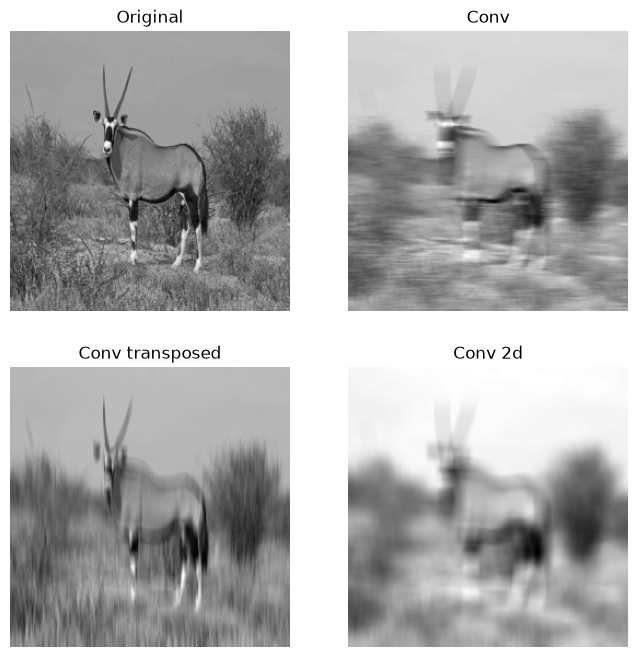

In [15]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(8, 8))

axs[0,0].imshow(oryx_gray, cmap='gray')
axs[0,0].axis('off')
axs[0,0].set_title("Original")
axs[0,1].imshow(img_oryx_mod_conv, cmap='gray')
axs[0,1].axis('off')
axs[0,1].set_title("Conv")
axs[1,0].imshow(img_oryx_mod_conv_transposed, cmap='gray')
axs[1,0].axis('off')
axs[1,0].set_title("Conv transposed")
axs[1,1].imshow(img_oryx_mod_conv_2d, cmap='gray')
axs[1,1].axis('off')
axs[1,1].set_title("Conv 2d")
plt.show()

### Effect of the Convolution Masks

> **1D Horizontal and Vertical Masks:**
These masks smooth the image in only one direction—horizontally or vertically. This produces directional blurring while preserving more details in the perpendicular direction. As a result, the pixel intensity range is moderately reduced.

> **2D Mask:**
This mask smooths the image in both horizontal and vertical directions simultaneously, producing a stronger overall blurring effect. Because it averages a larger neighborhood of pixels, it generally reduces the pixel intensity range more significantly.


**c) RGB Image Convolution with a 2D Filter**

- Implement a function called `conv_coor(image, mask)` that applies the same 2D filter independently to each of the three RGB channels.

- Resize the original `oryx.png` image to **256 × 256 pixels**, and test your function using a **7 × 7 uniform mask**.

- Visualize the result and compare the filtered RGB image with the original image.

> Expected output is illustrated below:

<img src="images_notebook/rgb_filtered.jpg">


(256, 256, 3) 0.009492300577272968 0.9920457655243662 float64


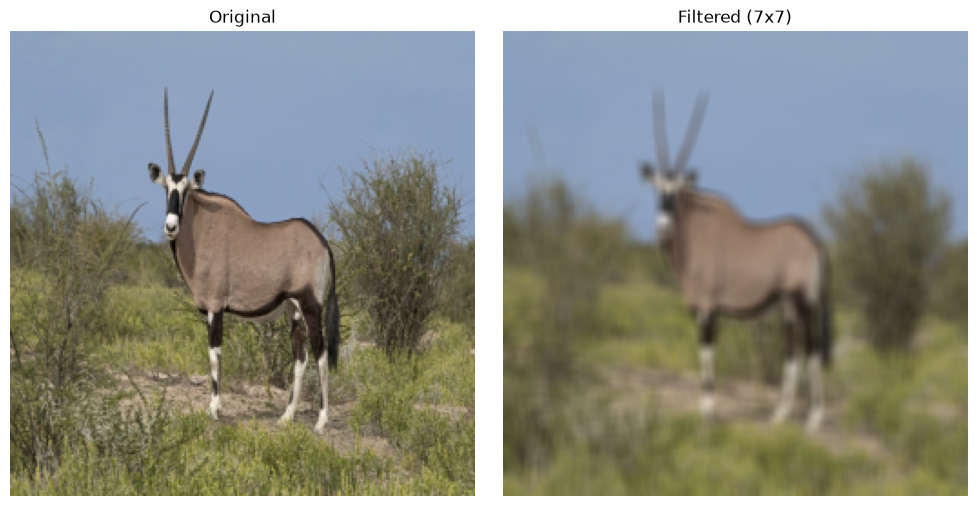

In [16]:
def conv_coor(image, mask):
    filtered_image = np.zeros_like(image, dtype=np.float64)

    filtered_image[:, :, 0] = convolve(image[:, :, 0], mask)
    filtered_image[:, :, 1] = convolve(image[:, :, 1], mask)
    filtered_image[:, :, 2] = convolve(image[:, :, 2], mask)

    return filtered_image
    

image_resized = resize(img_oryx, (256, 256), anti_aliasing=True)                                        # float 64 [0,1]
print(image_resized.shape, image_resized.min(), image_resized.max(), image_resized.dtype)
plt.figure(figsize=(10, 5))

plt.subplot(1,2,1)
plt.imshow(image_resized)
plt.title("Original")
plt.axis('off')

mask = np.ones((7,7), dtype=np.uint8)
mask = mask / np.sum(mask)
filtered_image = conv_coor(image_resized, mask)

plt.subplot(1,2,2)
plt.imshow(filtered_image)
plt.title("Filtered (7x7)")
plt.axis('off')

plt.tight_layout()
plt.show()

## **2.3 Effect of image scale on convolutions**

**a)** Image Rescaling and Histogram Analysis

Resize the grayscale image `oryx_gray` and observe how the image histogram changes.

1. **Reduce** `oryx_gray` by a factor of 20 and compute its histogram using `nbins = 64`.
2. **Enlarge** `oryx_gray` by a factor of 20 and compute its histogram using `nbins = 64`.
3. Display the histograms of the original, reduced, and enlarged images side by side and compare them.

**Question:**
Are there any differences between the histograms? Explain what happens and why the histogram may change after rescaling the image.

> Expected output is illustrated below:

<img src="images_notebook/resize_impact.jpg">


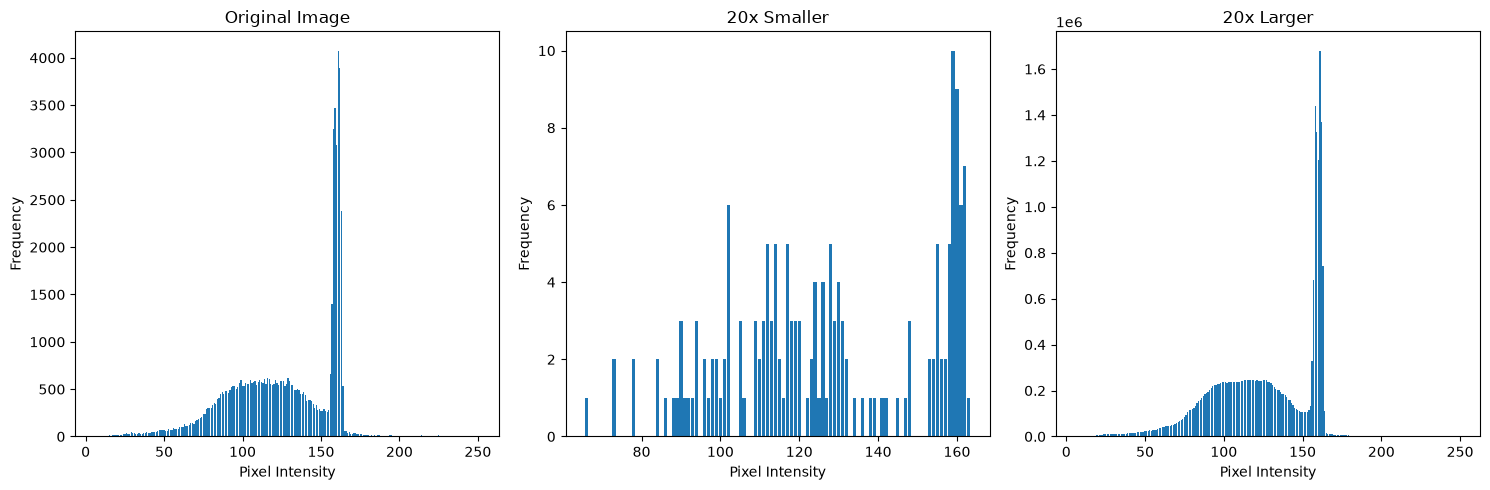

In [17]:
from skimage.exposure import histogram
from skimage.transform import rescale

nbins = 64
img_oryx20 = rescale(oryx_gray, 1/20, preserve_range=True, anti_aliasing=True).astype(np.uint8)
img_oryx_20 = rescale(oryx_gray, 20, preserve_range=True, anti_aliasing=True).astype(np.uint8)

hist, bin_centers = histogram(oryx_gray, nbins)
hist20_div, bin_centers20_div = histogram(img_oryx20, nbins)
hist20_mult, bin_centers20_mult = histogram(img_oryx_20, nbins)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].bar(bin_centers, hist)
ax[0].set_title("Original Image")
ax[0].set_xlabel("Pixel Intensity")
ax[0].set_ylabel("Frequency")

ax[1].bar(bin_centers20_div, hist20_div)
ax[1].set_title("20x Smaller")
ax[1].set_xlabel("Pixel Intensity")
ax[1].set_ylabel("Frequency")

ax[2].bar(bin_centers20_mult, hist20_mult)
ax[2].set_title("20x Larger")
ax[2].set_xlabel("Pixel Intensity")
ax[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Explanation**

> **Do your analysis here!**

**b) Convolution and Histogram Analysis**

Apply a **7 × 7 uniform convolution mask** to the images from the previous exercise, compute their histograms, and compare the results.

1. **Plot the original `oryx_gray` image and its histogram** for reference.

2. Convolve the original `oryx_gray` image and compute its histogram.

3. Convolve the **reduced `oryx_gray` image from the previous exercise** and compute its histogram.

4. Convolve the **enlarged `oryx_gray` image from the previous exercise** and compute its histogram.

**Note:** Display the images in the **top row** and their corresponding histograms in the **bottom row**, using `nbins = 32`.

**Question:**
Compare the original and filtered images and their histograms. What differences do you observe, and why do these differences occur?

> Expected output is illustrated below:

<img src="images_notebook/oryx_filtered2.jpg">

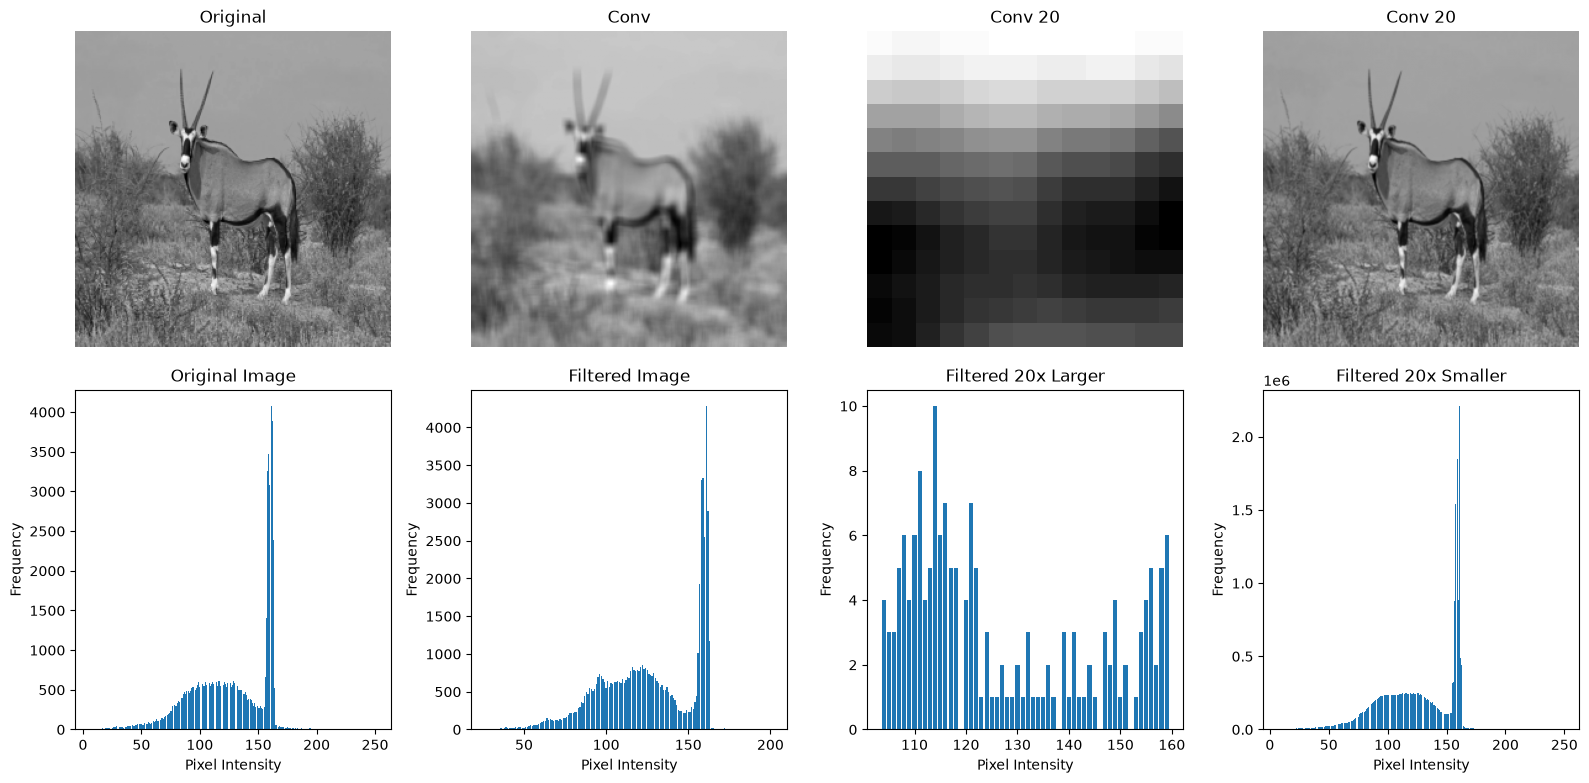

In [18]:
mask = np.ones((7,7), dtype=np.uint8)
mask = mask / np.sum(mask)



img_oryx_conv = convolve(oryx_gray, mask)
img_oryx20_conv = convolve(img_oryx20, mask)
img_oryx_20_conv = convolve(img_oryx_20, mask)

numberOfBins = 32

fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axs[0,0].imshow(oryx_gray, cmap='gray')
axs[0,0].axis('off')
axs[0,0].set_title("Original")
axs[0,1].imshow(img_oryx_conv, cmap='gray')
axs[0,1].axis('off')
axs[0,1].set_title("Conv")
axs[0,2].imshow(img_oryx20_conv, cmap='gray')
axs[0,2].axis('off')
axs[0,2].set_title("Conv 20")
axs[0,3].imshow(img_oryx_20_conv, cmap='gray')
axs[0,3].axis('off')
axs[0,3].set_title("Conv 20")

hist, bin_centers = histogram(oryx_gray, nbins=numberOfBins)
hist_filtered, bin_centers_filtered = histogram(img_oryx_conv, nbins=numberOfBins)
hist20_mult, bin_centers20_mult = histogram(img_oryx20_conv, nbins=numberOfBins)
hist20_div, bin_centers20_div = histogram(img_oryx_20_conv, nbins=numberOfBins)

axs[1,0].bar(bin_centers, hist)
axs[1,0].set_title("Original Image")
axs[1,0].set_xlabel("Pixel Intensity")
axs[1,0].set_ylabel("Frequency")
axs[1,1].bar(bin_centers_filtered, hist_filtered)
axs[1,1].set_title("Filtered Image")
axs[1,1].set_xlabel("Pixel Intensity")
axs[1,1].set_ylabel("Frequency")
axs[1,2].bar(bin_centers20_mult, hist20_mult)
axs[1,2].set_title("Filtered 20x Larger")
axs[1,2].set_xlabel("Pixel Intensity")
axs[1,2].set_ylabel("Frequency")
axs[1,3].bar(bin_centers20_div, hist20_div)
axs[1,3].set_title("Filtered 20x Smaller")
axs[1,3].set_xlabel("Pixel Intensity")
axs[1,3].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Explanation**

> **Do your analysis here!**



## **2.4 Image processing with weighting and non-linear filters**

**a) Generate the following kernels and apply them to the `oryx_gray` image:**

1. Generate a Gaussian kernel with σ = 1 and apply it to the image.
2. Generate Gaussian kernels with three different σ values (0.5, 2, and 3) and apply them to the image. Which σ value is the most appropriate for preserving the main objects and structures in the image?
3. Apply a median filter using different mask shapes: disk, rectangle, and diamond. Apply the median filter using different mask sizes for each shape: `disk(5)`, `rectangle(5,20)`, and `diamond(3)`, and compare their effects on the original image. What is the effect of using the different mask shapes on the original image?

> **Note:** For the disk and diamond filters, the specified value represents the **radius in pixels**, while `morphology.rectangle(5, 20)` specifies the **height and width of the rectangular structuring element (5 × 20 pixels)**.


Comment on the effects of the different filters on the original image.

**Hint:** 
- Search for the [skimage.filters function](https://scikit-image.org/docs/stable/api/skimage.filters.html) for creating the different filters.
- Also check [scikit-image — skimage.morphology documentation](https://scikit-image.org/docs/stable/api/skimage.morphology)

> Expected output is illustrated below:

<img src="images_notebook/filter.jpg">


/var/folders/6f/18hypst910ngtsstkk4y6vfh0000gn/T/ipykernel_29777/1119732753.py:11: FutureWarning: `rectangle` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  oryx_gray_median_rectangle_5x20 = median(oryx_gray, rectangle(5, 20))


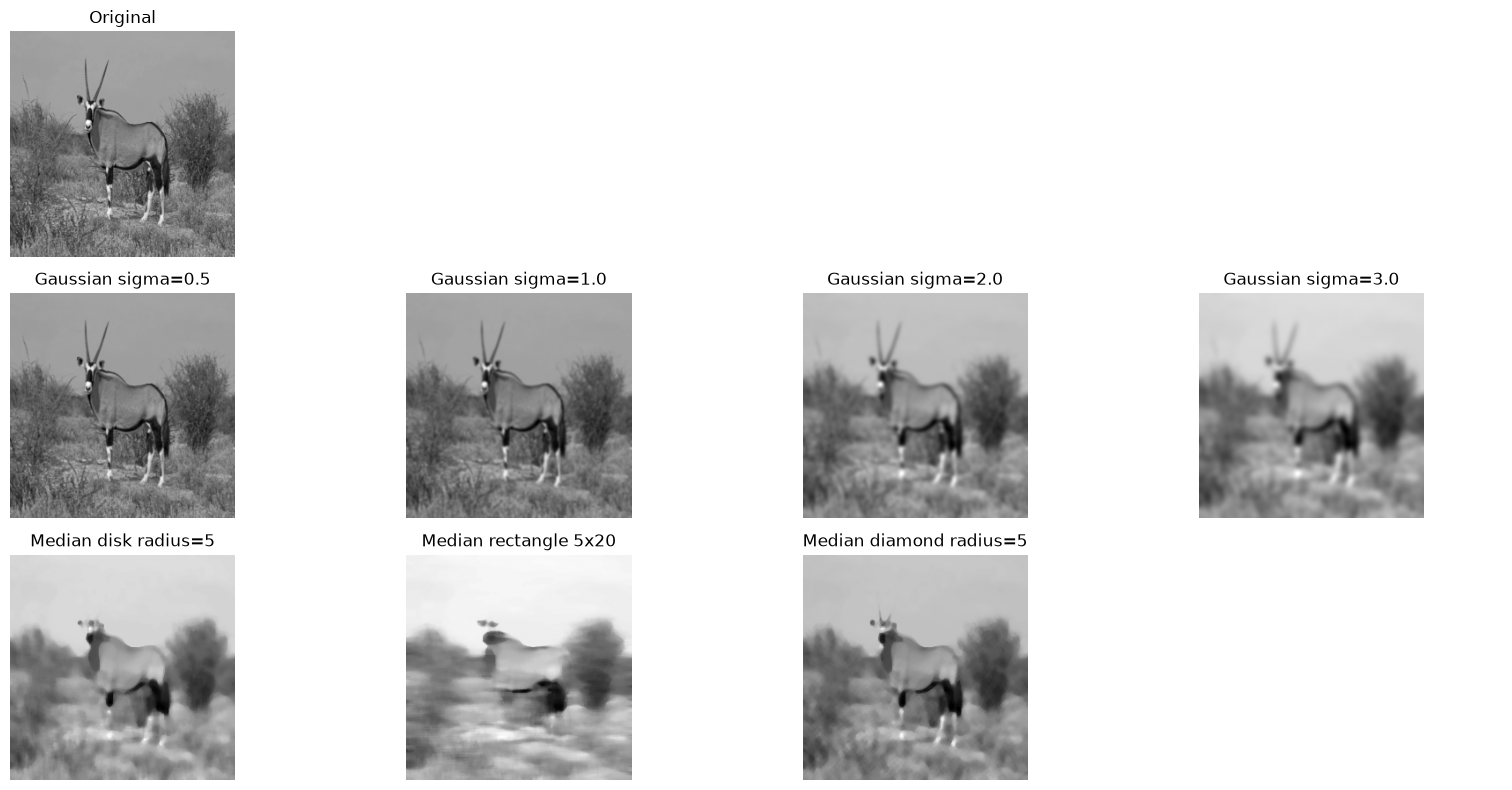

In [19]:
from skimage.filters import gaussian, median
from skimage.morphology import disk, rectangle, diamond
import matplotlib.pyplot as plt

oryx_gray_gaussian_05 = gaussian(oryx_gray, sigma=0.5)
oryx_gray_gaussian_10 = gaussian(oryx_gray, sigma=1.0)
oryx_gray_gaussian_20 = gaussian(oryx_gray, sigma=2.0)
oryx_gray_gaussian_30 = gaussian(oryx_gray, sigma=3.0)

oryx_gray_median_radius_5 = median(oryx_gray, disk(5))
oryx_gray_median_rectangle_5x20 = median(oryx_gray, rectangle(5, 20))
oryx_gray_median_diamond_5 = median(oryx_gray, diamond(5))

fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(16, 8))

axs[0,0].imshow(oryx_gray, cmap='gray')
axs[0,0].axis('off')
axs[0,0].set_title("Original")
axs[0,1].axis('off')
axs[0,2].axis('off')
axs[0,3].axis('off')
axs[1,0].imshow(oryx_gray_gaussian_05, cmap='gray')
axs[1,0].axis('off')
axs[1,0].set_title("Gaussian sigma=0.5")
axs[1,1].imshow(oryx_gray_gaussian_10, cmap='gray')
axs[1,1].axis('off')
axs[1,1].set_title("Gaussian sigma=1.0")
axs[1,2].imshow(oryx_gray_gaussian_20, cmap='gray')
axs[1,2].axis('off')
axs[1,2].set_title("Gaussian sigma=2.0")
axs[1,3].imshow(oryx_gray_gaussian_30, cmap='gray')
axs[1,3].axis('off')
axs[1,3].set_title("Gaussian sigma=3.0")

axs[2,0].imshow(oryx_gray_median_radius_5, cmap='gray')
axs[2,0].axis('off')
axs[2,0].set_title("Median disk radius=5")
axs[2,1].imshow(oryx_gray_median_rectangle_5x20, cmap='gray')
axs[2,1].axis('off')
axs[2,1].set_title("Median rectangle 5x20")
axs[2,2].imshow(oryx_gray_median_diamond_5, cmap='gray')
axs[2,2].axis('off')
axs[2,2].set_title("Median diamond radius=5")
axs[2,3].axis('off')

plt.tight_layout()
plt.show()

### Discussion

> **Do your analysis here!**



b) **(Optional)** Apply the smoothing on some other images and present their results.

In [20]:
#your solution

### **2.5 Comparison of Edge Detection Techniques**

**a)** Load the 'logo_pozo.jpg' image and visualize its contours.

<img src="images_notebook/logo_pozo.jpg" width="200" height="200">

First, convert it to gray scale. Then, apply the different contour extraction tecniques introduced during the theory session and change any parameter if necessary for detecting the edges of the image:

1. Prewitt
2. Sobel
3. Canny

Use subplot and title to visualize the results.

#### **Questions**

* What are the optimal parameter values for each method?
* Is it necessary to normalize the masks, as is commonly done when applying smoothing filters? Explain your answer.

**Hint:** Use `skimage.feature.canny` for the Canny edge detector and `skimage.filters` for the Prewitt and Sobel operators.

> Expected output is illustrated below:

<img src="images_notebook/edge.jpg">


> **Note:** Prewitt and Sobel produce grayscale images because they measure edge strength (gradient magnitude), whereas Canny applies thresholding to generate a binary image containing only the detected edges.



In [ ]:
# import warnings
# warnings.filterwarnings("ignore")
from skimage.feature import canny

def contour_analysis(img_route, smoothing = False):
    from skimage.filters import sobel, prewitt, sobel_v, sobel_h, prewitt_h, prewitt_v

    img = io.imread(img_route)
    img_gray = img_as_ubyte(rgb2gray(img))
    if smoothing:
        if smoothing == "gaussian":
            img_gray = gaussian(img_gray, sigma=1.0)
        elif smoothing == "median":
            img_gray = median(img_gray, disk(5))
    sobel = sobel(img_gray)
    prewitt = prewitt(img_gray)
    canny_1 = canny(img_gray, sigma=1.0)
    canny_2 = canny(img_gray, sigma=2.0)
    canny_3 = canny(img_gray, sigma=3.0)

    fig = plt.figure(figsize=(18, 8))
    fig.add_subplot(1, 5, 1)
    plt.imshow(prewitt, cmap='gray')
    plt.title('Prewitt Edge Detection')
    plt.axis('off')
    fig.add_subplot(1, 5, 2)
    plt.imshow(sobel, cmap='gray')
    plt.title('Sobel Edge Detection')
    plt.axis('off')
    fig.add_subplot(1, 5, 3)
    plt.imshow(canny_1, cmap='gray')
    plt.title('Canny Edge Detection (σ=1.0)')
    plt.axis('off')
    fig.add_subplot(1, 5, 4)
    plt.imshow(canny_2, cmap='gray')
    plt.title('Canny Edge Detection (σ=2.0)')
    plt.axis('off')
    fig.add_subplot(1, 5, 5)
    plt.imshow(canny_3, cmap='gray')
    plt.title('Canny Edge Detection (σ=3.0)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

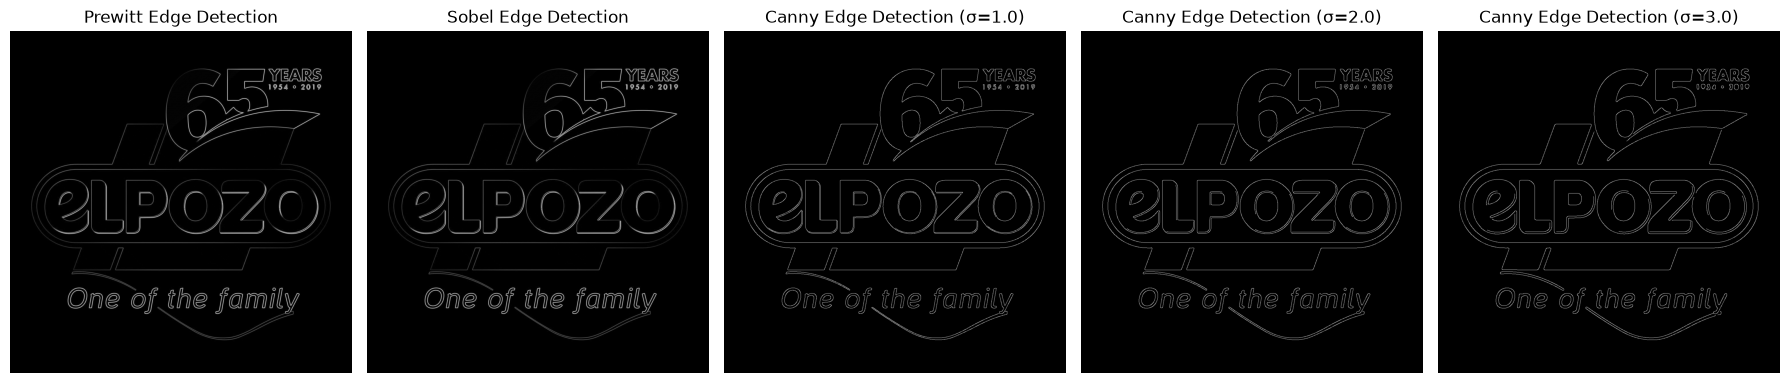

In [52]:
contour_analysis("./images_notebook/logo_pozo.jpg")

## Questions & Answers

### 1. What are the optimal parameter values for each method?

* **Sobel and Prewitt Operators (`skimage.filters.sobel` / `skimage.filters.prewitt`):**
  * **Parameters:** These functions do not require or take tunable parameters for standard execution in scikit-image. They operate using fixed 3x3 derivative kernels optimized to calculate gradient magnitudes.
* **Canny Edge Detector (`skimage.feature.canny`):**
  * **Optimal Parameter Values:** 
    * **`sigma`**: Typically between **`1.0` and `2.0`** (e.g., `sigma=1.0` works well for cleaner images; higher values like `sigma=2.0` help suppress more noise in complex or textured backgrounds).
    * **`low_threshold` & `high_threshold`**: Can be left to default (which automatically calculates thresholds based on image percentiles), or manually adjusted depending on contrast (e.g., lower percentiles for weak edges, higher for strong edges).

### 2. Is it necessary to normalize the masks, as is commonly done when applying smoothing filters? Explain your answer.

* **No, it is not necessary—and doing so would break the filter.**
* **Explanation:** 
  * **Smoothing filters** (like a uniform/mean blur mask) are designed to average pixel intensities. Their coefficients must sum to **1** (normalized) to ensure that the overall brightness of the image is preserved.
  * **Edge detection filters** (like Sobel and Prewitt) are **derivative operators** designed to measure changes (gradients) in intensity. Their kernels (e.g., containing positive and negative values) are specifically designed to sum to **0**. 
  * If you normalized an edge detection mask so that its elements summed to 1, a flat, uniform region in the image would incorrectly produce a non-zero output value instead of `0`. The zero-sum property is mathematically required for derivative filters to cancel out constant background areas and only highlight regions of rapid intensity change.

**b)**	Repeat the experiment with other images, you can use the ones included in the folder **images** (`cr.jpg` and `messi.jpg`). 
- Comment if some parameter needs to be changed for the different images.
- Answer: No

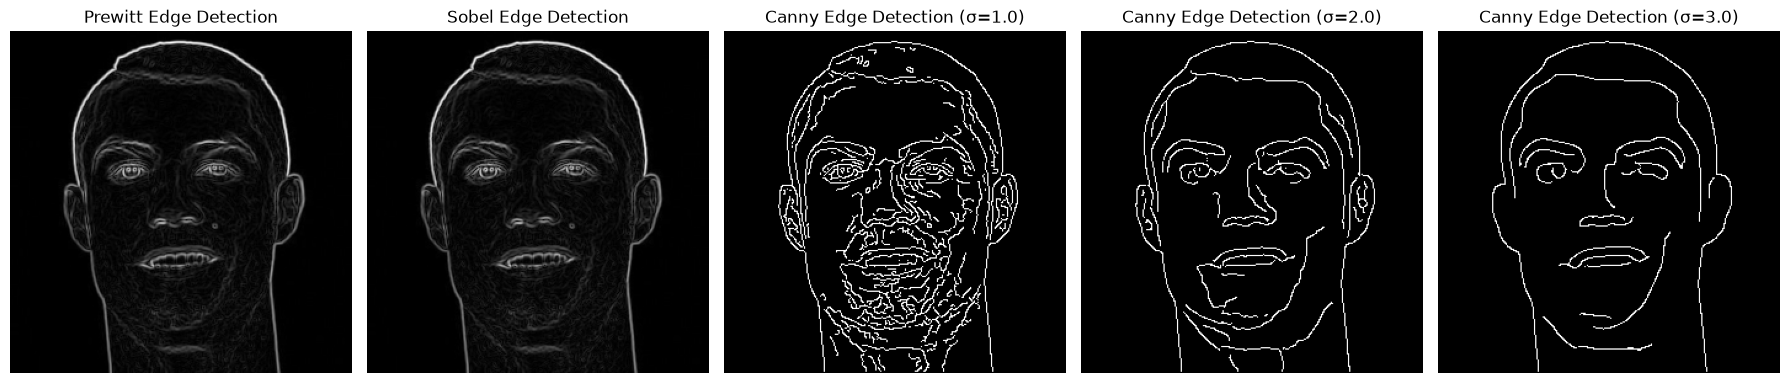

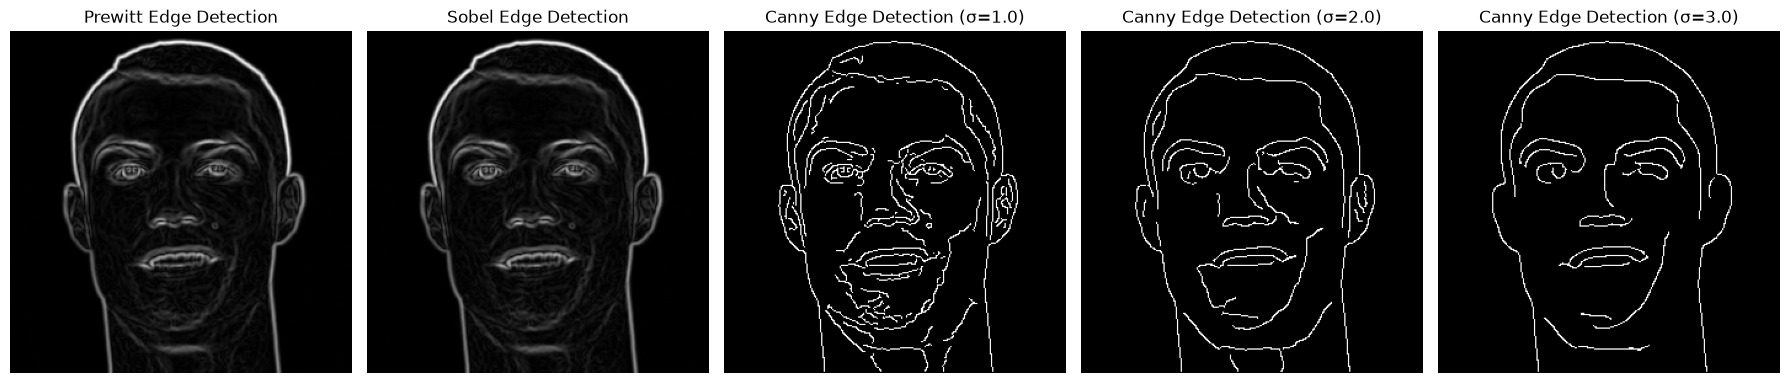

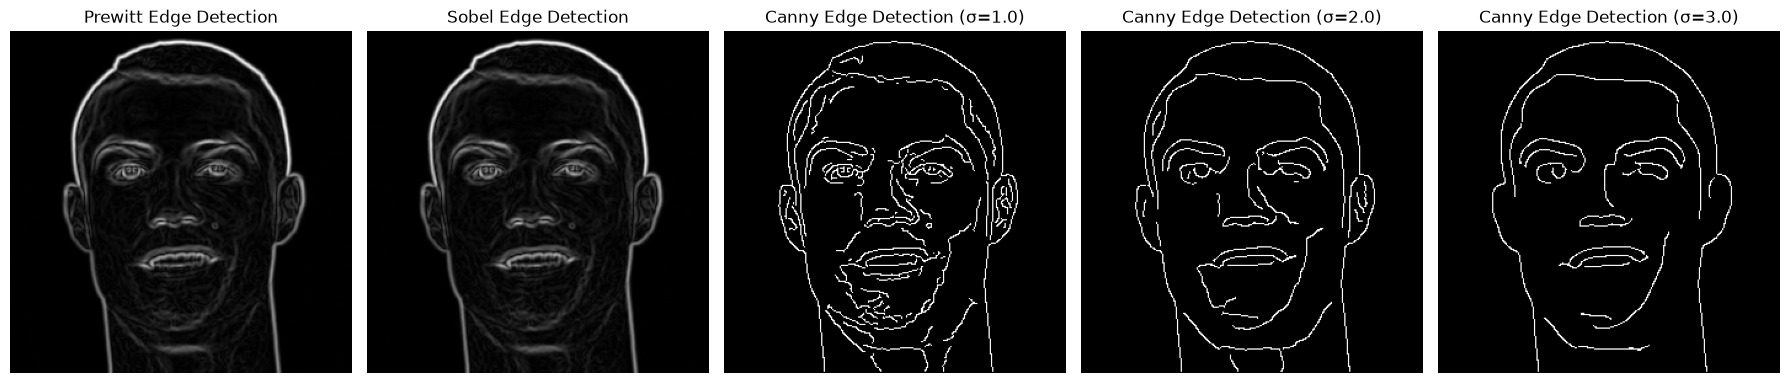

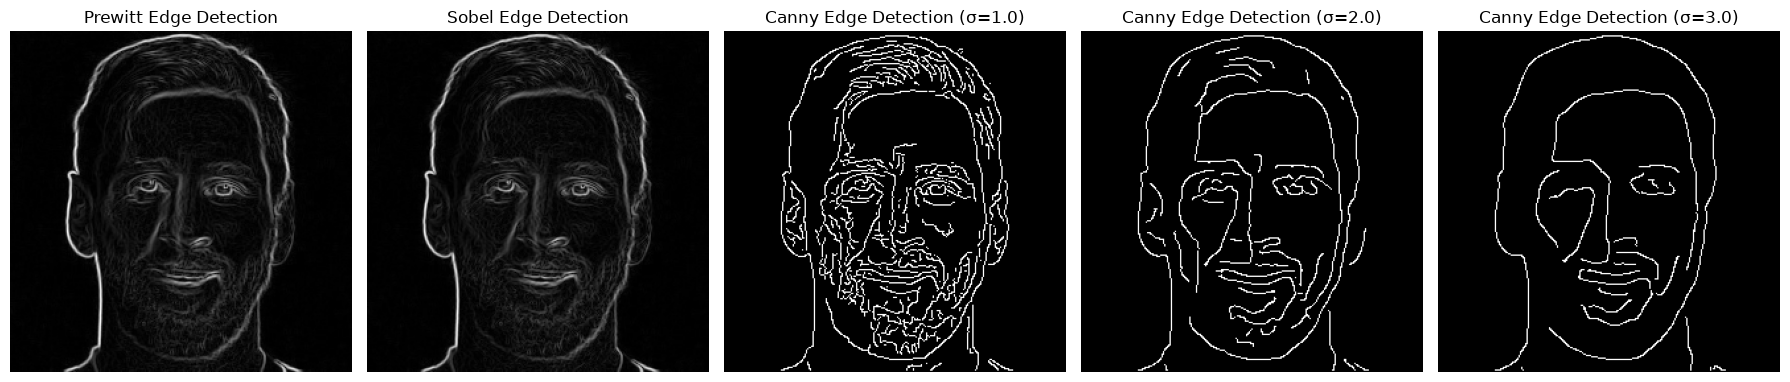

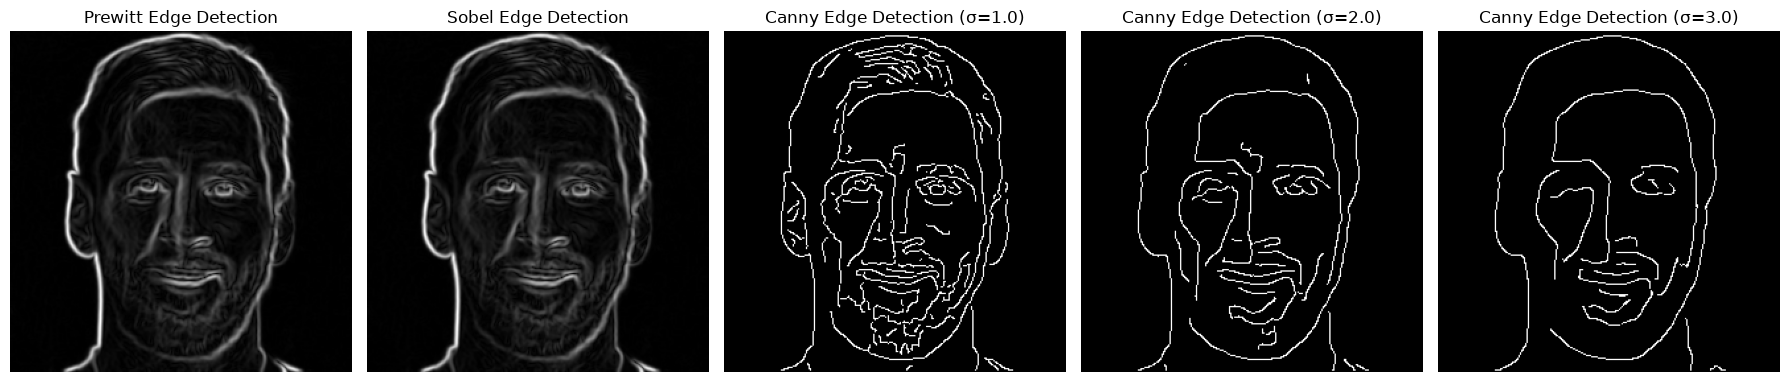

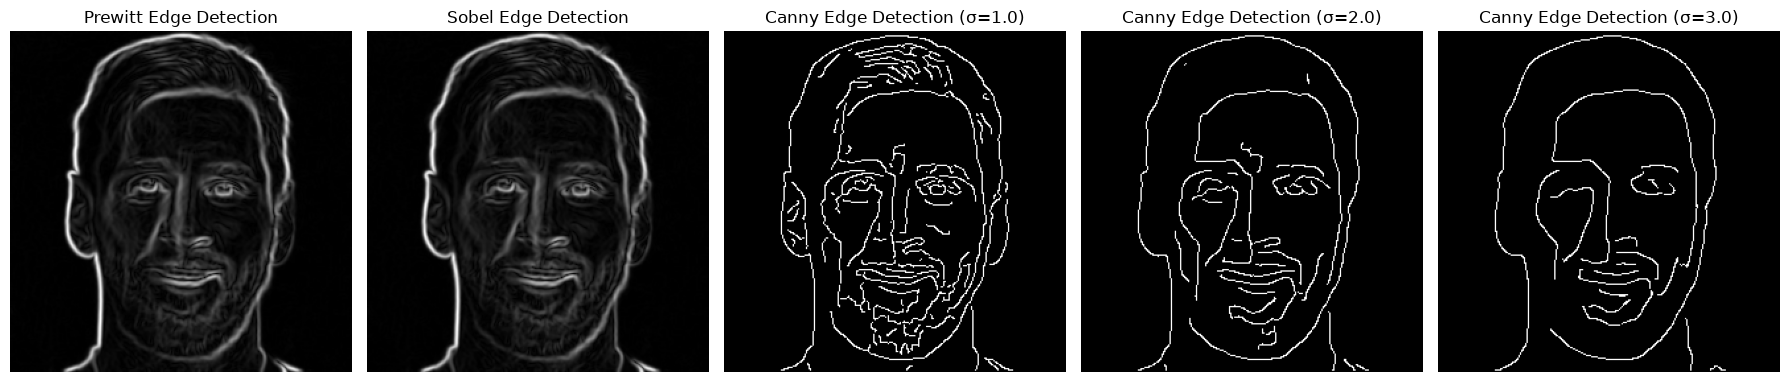

In [56]:
contour_analysis("./images_notebook/cr.jpg")
contour_analysis("./images_notebook/cr.jpg", smoothing="gaussian")
contour_analysis("./images_notebook/cr.jpg", smoothing="median")
contour_analysis("./images_notebook/messi.jpg")
contour_analysis("./images_notebook/messi.jpg", smoothing="gaussian")
contour_analysis("./images_notebook/messi.jpg", smoothing="median")


# Discussion Analysis

## 1. Does applying smoothing before edge detection improve the detected contours?

* **Yes, it generally improves contour detection by reducing noise.** 
* **Explanation:** Edge detection algorithms (like Sobel, Prewitt, and Canny) rely on calculating image gradients (first-order derivatives). Derivatives are mathematically very sensitive to high-frequency variations, meaning random pixel noise or fine background textures can easily trigger false or fragmented edges. 
* **The Role of Smoothing:** Applying a Gaussian filter beforehand suppresses this high-frequency noise, ensuring that the edge detector focuses only on significant structural boundaries rather than random pixel fluctuations.
* **The Trade-off:** While smoothing stabilizes edge detection, excessive smoothing (e.g., using a high `sigma` value) can blur out fine, sharp, or low-contrast true edges, causing them to disappear or shift slightly in location. Therefore, a balance is required.

---

## 2. What are the limitations of the different edge detection methods?

### Sobel and Prewitt Operators
* **High Noise Sensitivity:** Because they calculate gradients directly without any built-in smoothing, they are easily affected by image noise, producing spurious edges in textured regions.
* **Thick Edges:** They output a continuous gradient magnitude map rather than thin, precise lines, often requiring additional post-processing (like thresholding or thinning) to get clean boundaries.
* **Manual Thresholding Required:** They produce grayscale gradient images, meaning a threshold must be manually defined to convert them into binary contour maps.

### Canny Edge Detector
* **Computational Complexity:** Canny is a multi-stage algorithm (Gaussian smoothing, gradient calculation, non-maximum suppression, and double-threshold hysteresis), making it computationally heavier and slower than simple gradient masks.
* **Parameter Sensitivity:** It requires tuning multiple interdependent parameters (Gaussian `sigma`, `low_threshold`, and `high_threshold`). Incorrect tuning can either result in broken contours (gaps in edges) or too much unwanted background noise.
* **Over-smoothing Risk:** If the initial Gaussian smoothing step uses a high `sigma` to clean up a noisy image, fine details and subtle edges can be completely wiped out before edge tracking even begins.

**c)** Implement the Sobel and Prewitt edge detection operators manually using the `convolve` function instead of the implementations provided by `skimage.filters`.

- Define the corresponding horizontal and vertical kernels for each operator, apply them to the image using convolution, and compute the gradient magnitude from the resulting responses.

- Visualize the results and compare them with those obtained using `skimage.filters.sobel` and `skimage.filters.prewitt`.

> Expected output is illustrated below:

<img src="images_notebook/implemented_detectors.jpg">

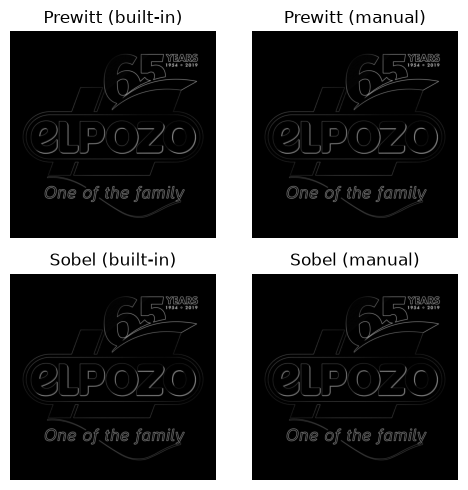

In [62]:
from skimage.util import img_as_ubyte
from skimage.filters import sobel, prewitt

img_pozo = io.imread("./images_notebook/logo_pozo.jpg") # important: no utilizar img_as_ubyte aquí, perquè rgb2gray torna un array de floats entre 0 i 1, i després img_as_ubyte el converteix a uint8 entre 0 i 255, el que no és correcte per a la detecció de contorns, ja que en fer màscares tots els valors negatius es converteixen a 0, i per tant es perd informació. Per això, és millor treballar amb floats entre 0 i 1.
img_pozo_gray = rgb2gray(img_pozo)

sobel_gx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
sobel_gy = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=np.float64)

prewitt_gx = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float64)
prewitt_gy = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1]
], dtype=np.float64)

img_pozo_sobel_gx = convolve(img_pozo_gray, sobel_gx)
img_pozo_sobel_gy = convolve(img_pozo_gray, sobel_gy)
img_pozo_prewitt_gx = convolve(img_pozo_gray, prewitt_gx)
img_pozo_prewitt_gy = convolve(img_pozo_gray, prewitt_gy)

img_pozo_sobel = np.sqrt(img_pozo_sobel_gx**2 + img_pozo_sobel_gy**2)
img_pozo_prewitt = np.sqrt(img_pozo_prewitt_gx**2 + img_pozo_prewitt_gy**2)

img_pozo_prewitt_built_in = prewitt(img_pozo_gray)
img_pozo_sobel_built_in = sobel(img_pozo_gray)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))
axs[0, 0].imshow(img_pozo_prewitt_built_in, cmap='gray')
axs[0 , 1].imshow(img_pozo_prewitt, cmap='gray')
axs[1, 0].imshow(img_pozo_sobel_built_in, cmap='gray')
axs[1, 1].imshow(img_pozo_sobel, cmap='gray')

axs[0, 0].set_title("Prewitt (built-in)")
axs[0, 1].set_title("Prewitt (manual)")
axs[1, 0].set_title("Sobel (built-in)")
axs[1, 1].set_title("Sobel (manual)")
axs[0, 0].axis('off')
axs[0, 1].axis('off')
axs[1, 0].axis('off')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()


### 2.6 Applying smoothing in order to obtain hybrid images

**a)** Given `./images_notebook/messi.jpg` and `./images_notebook/cr.jpg` images:

1. Plot both images.
2. Apply a low-pass filter to both of them and plot them.
3. Apply a high-pass filter to both of them and plot them.

The result should be something like:


<img src="images_notebook/Messi.png" height="200">
<img src="images_notebook/CR.png" height="200">


By applying smoothing over an image I, we apply a `low-pass` filter. The resulting image can be called L(I). If we substract the filtered one from the original image, we obtain its high frequencies, that we can call H(I), i.e. we apply a `high-pass` filter.

***H(I) = I - L(I)***

***Hint:*** In order to highlight the effect, in the L(I) image you should define a lower sigma.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5509509395188888..0.43315259602927114].


(256, 256, 3) 0.0 0.9999740002202052 float64
(256, 256, 3) 0.009527408104275749 0.8647842202149545 float64
(256, 256, 3) -0.5509509395188888 0.43315259602927114 float64


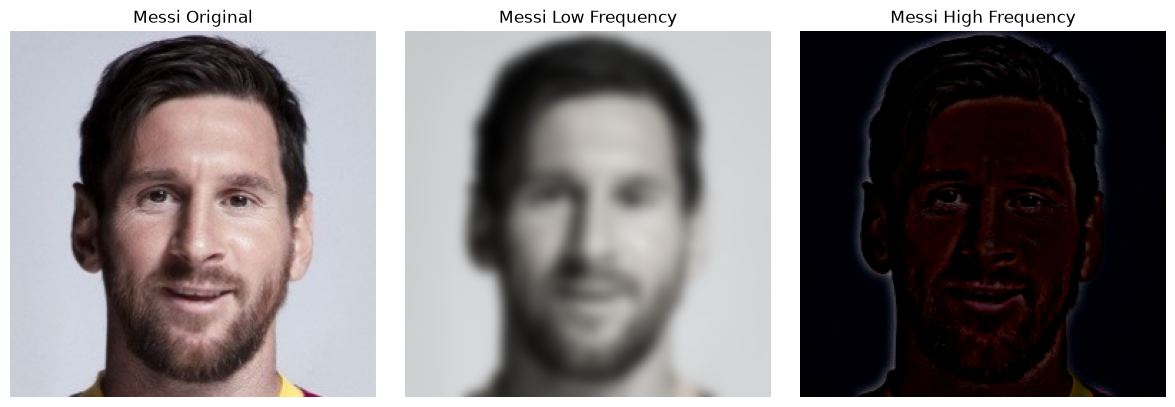

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5819555991798853..0.4425755593363759].


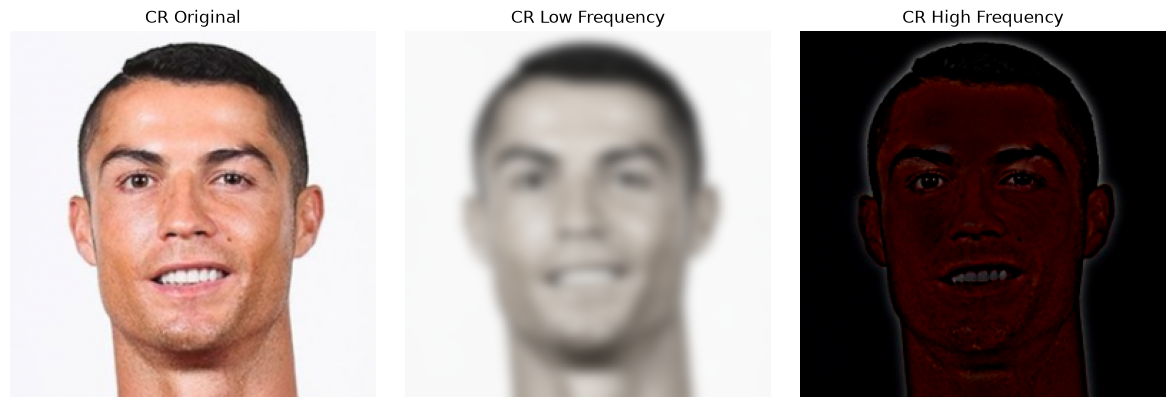

In [95]:
from skimage import io
from skimage.filters import gaussian

sigma = 4.0

img_messi = resize(io.imread("./images_notebook/messi.jpg"), (256, 256))
img_cr = resize(io.imread("./images_notebook/cr.jpg"), (256, 256))

print(img_messi.shape, img_messi.min(), img_messi.max(), img_messi.dtype)
img_messi_lf = gaussian(img_messi, sigma)
img_cr_lf = gaussian(img_cr, sigma)

print(img_messi_lf.shape, img_messi_lf.min(), img_messi_lf.max(), img_messi_lf.dtype)

img_messi_hi = img_messi - img_messi_lf
img_cr_hi = img_cr - img_cr_lf

print(img_messi_hi.shape, img_messi_hi.min(), img_messi_hi.max(), img_messi_hi.dtype)

def plot_frequency_components(img_gray, img_lf, img_hi, title):
    fig = plt.figure(figsize=(12, 4))
    fig.add_subplot(1, 3, 1)
    plt.imshow(img_gray)
    plt.title(f'{title} Original')
    plt.axis('off')

    fig.add_subplot(1, 3, 2)
    plt.imshow(img_lf)
    plt.title(f'{title} Low Frequency')
    plt.axis('off')

    fig.add_subplot(1, 3, 3)
    plt.imshow(img_hi)
    plt.title(f'{title} High Frequency')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

plot_frequency_components(img_messi, img_messi_lf, img_messi_hi, "Messi")
plot_frequency_components(img_cr, img_cr_lf, img_cr_hi, "CR")

**b)** Create hybrid images and visualize them. A hybrid image is obtained by combining the low and high frequencies of the image, i.e. combining the results obtained by the `low-pass` and `high-pass` filters.

***Hybrid (I1, I2) = L(I1) + H(I2)***

### Exercise: Create Hybrid Images

Using the low- and high-frequency components obtained from the `messi` and `cr` images, create two hybrid images.

1. Create **Hybrid Image 1** by combining the low-frequency component of `cr` with the high-frequency component of `messi`, giving both components equal weight (`0.5`).
2. Create **Hybrid Image 2** by combining the low-frequency component of `messi` with the high-frequency component of `cr`, also giving both components equal weight (`0.5`).
3. Multiply each result by `2` to compensate for the averaging.
4. Display both hybrid images side by side in a `1 × 2` grid, without axes, and with appropriate titles.

> Expected result is shown below:

<img src="images_notebook/Hybrid.png" height="200">


> Hybrid images can be used in **visual illusions, art and design, advertising, visual perception research, and computer vision applications**, where different details are perceived at different viewing distances.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0063888116647898285..1.3258782154010378].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.3562548746451015..1.1509587579518028].


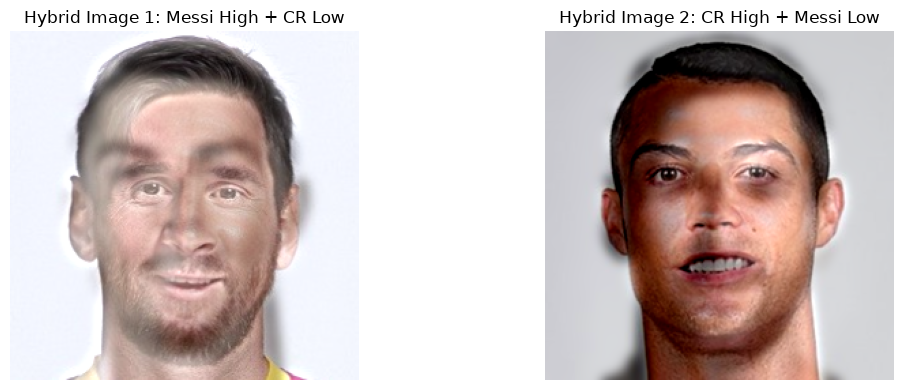

In [ ]:
hybrid_image1 = img_messi_hi + img_cr_lf
hybrid_image2 = img_cr_hi + img_messi_lf

# hybrid_image1 *= 2
# hybrid_image2 *= 2

fig = plt.figure(figsize=(12, 4))
fig.add_subplot(1, 2, 1)
plt.imshow(hybrid_image1)
plt.title('Hybrid Image 1: Messi High + CR Low')
plt.axis('off')
fig.add_subplot(1, 2, 2)
plt.imshow(hybrid_image2)
plt.title('Hybrid Image 2: CR High + Messi Low')
plt.axis('off')
plt.tight_layout()
plt.show()

## **2.7 Anonimization of sensitive information**

One of the important problems in Computer Vision as a science that manages data (images and videos) is the anonimization of sensitive information appearing in the images.
For example, it is common in applications like Google Street View, where the faces and license plates are anonymized.
The file `./images_notebook/car.png` contains two cars. Anonimize the license plates of the cars using the techniques learned in this practicum.

Modify only the license plates of the cars, keeping the rest of the image unchanged.

Expected result is illustrated below:

<img src="images_notebook/anonimyzed.jpg" height="350">

In [ ]:
# your solution



